 # NHS A&E 4-Hour Waits – England, October 2026

This project analyses NHS England A&E data for October 2026 to find which hospitals have the longest waits. The NHS target is for patients to be seen within 4 hours. Data source: NHS England, Monthly A&E Attendances and Emergency Admissions.

In [17]:
import pandas as pd
df = pd.read_csv("October-2026-CSV-WD35qg.csv")

In [18]:
df.head()

,Period,Org Code,Parent Org,Org name,A&E attendances Type 1,A&E attendances Type 2,A&E attendances Other A&E Department,A&E attendances Booked Appointments Type 1,A&E attendances Booked Appointments Type 2,A&E attendances Booked Appointments Other Department,...,Attendances over 4hrs Other Department,Attendances over 4hrs Booked Appointments Type 1,Attendances over 4hrs Booked Appointments Type 2,Attendances over 4hrs Booked Appointments Other Department,Patients who have waited 4-12 hs from DTA to admission,Patients who have waited 12+ hrs from DTA to admission,Emergency admissions via A&E - Type 1,Emergency admissions via A&E - Type 2,Emergency admissions via A&E - Other A&E department,Other emergency admissions
0,MSitAE-OCTOBER-2026,RAN,NHS ENGLAND LONDON,ROYAL NATIONAL ORTHOPAEDIC HOSPITAL NHS TRUST,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,31
1,MSitAE-OCTOBER-2026,RYY,NHS ENGLAND SOUTH EAST,KENT COMMUNITY HEALTH NHS FOUNDATION TRUST,0,0,6305,0,0,0,...,47,0,0,0,0,0,0,0,0,0
2,MSitAE-OCTOBER-2026,Y02676,NHS ENGLAND SOUTH EAST,BRIGHTON STATION HEALTH CENTRE,0,0,2065,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,MSitAE-OCTOBER-2026,C82038,NHS ENGLAND MIDLANDS,LATHAM HOUSE MEDICAL PRACTICE,0,0,394,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,MSitAE-OCTOBER-2026,C83023,NHS ENGLAND MIDLANDS,SLEAFORD MEDICAL GROUP,0,0,520,0,0,0,...,0,0,0,0,0,0,0,0,0,10


In [19]:
df.shape

(192, 22)

In [20]:
df.columns

Index(['Period', 'Org Code', 'Parent Org', 'Org name',
       'A&E attendances Type 1', 'A&E attendances Type 2',
       'A&E attendances Other A&E Department',
       'A&E attendances Booked Appointments Type 1',
       'A&E attendances Booked Appointments Type 2',
       'A&E attendances Booked Appointments Other Department',
       'Attendances over 4hrs Type 1', 'Attendances over 4hrs Type 2',
       'Attendances over 4hrs Other Department',
       'Attendances over 4hrs Booked Appointments Type 1',
       'Attendances over 4hrs Booked Appointments Type 2',
       'Attendances over 4hrs Booked Appointments Other Department',
       'Patients who have waited 4-12 hs from DTA to admission',
       'Patients who have waited 12+ hrs from DTA to admission',
       'Emergency admissions via A&E - Type 1',
       'Emergency admissions via A&E - Type 2',
       'Emergency admissions via A&E - Other A&E department',
       'Other emergency admissions'],
      dtype='str')

In [21]:
hospitals = df[df["A&E attendances Type 1"] > 0]

In [22]:
hospitals.shape

(121, 22)

In [23]:
hospitals["% over 4hrs"] = hospitals["Attendances over 4hrs Type 1"] / hospitals["A&E attendances Type 1"] * 100

In [24]:
hospitals.sort_values("% over 4hrs", ascending=False)[["Org name", "% over 4hrs"]].head(10)

,Org name,% over 4hrs
109,UNIVERSITY HOSPITALS PLYMOUTH NHS TRUST,63.123215
124,NORTH TEES AND HARTLEPOOL NHS FOUNDATION TRUST,62.389706
75,KINGSTON AND RICHMOND NHS FOUNDATION TRUST,59.198144
185,WIRRAL UNIVERSITY TEACHING HOSPITAL NHS FOUNDA...,57.717042
119,"WRIGHTINGTON, WIGAN AND LEIGH TEACHING HOSPITA...",57.189015
82,UNIVERSITY HOSPITALS OF NORTH MIDLANDS NHS TRUST,57.036429
125,HULL UNIVERSITY TEACHING HOSPITALS NHS TRUST,56.301606
132,THE SHREWSBURY AND TELFORD HOSPITAL NHS TRUST,56.196856
76,YORK AND SCARBOROUGH TEACHING HOSPITALS NHS FO...,54.625819
164,NOTTINGHAM UNIVERSITY HOSPITALS NHS TRUST,54.002869


In [25]:
hospitals["Attendances over 4hrs Type 1"].sum() / hospitals["A&E attendances Type 1"].sum() * 100

np.float64(40.05610000355313)

In [26]:
top10 = hospitals.sort_values("% over 4hrs", ascending=False).head(10)


In [27]:
hospitals.sort_values("% over 4hrs", ascending=True)[["Org name", "% over 4hrs"]].head(10)

,Org name,% over 4hrs
140,ALDER HEY CHILDREN'S NHS FOUNDATION TRUST,12.204969
65,SHEFFIELD CHILDREN'S NHS FOUNDATION TRUST,12.505418
47,CALDERDALE AND HUDDERSFIELD NHS FOUNDATION TRUST,17.149701
44,HOMERTON HEALTHCARE NHS FOUNDATION TRUST,22.277510
122,NORTHUMBRIA HEALTHCARE NHS FOUNDATION TRUST,22.609379
154,WHITTINGTON HEALTH NHS TRUST,24.769395
23,MAIDSTONE AND TUNBRIDGE WELLS NHS TRUST,25.095038
97,BRADFORD TEACHING HOSPITALS NHS FOUNDATION TRUST,25.191070
113,THE DUDLEY GROUP NHS FOUNDATION TRUST,25.331276
156,BIRMINGHAM WOMEN'S AND CHILDREN'S NHS FOUNDATI...,26.844158


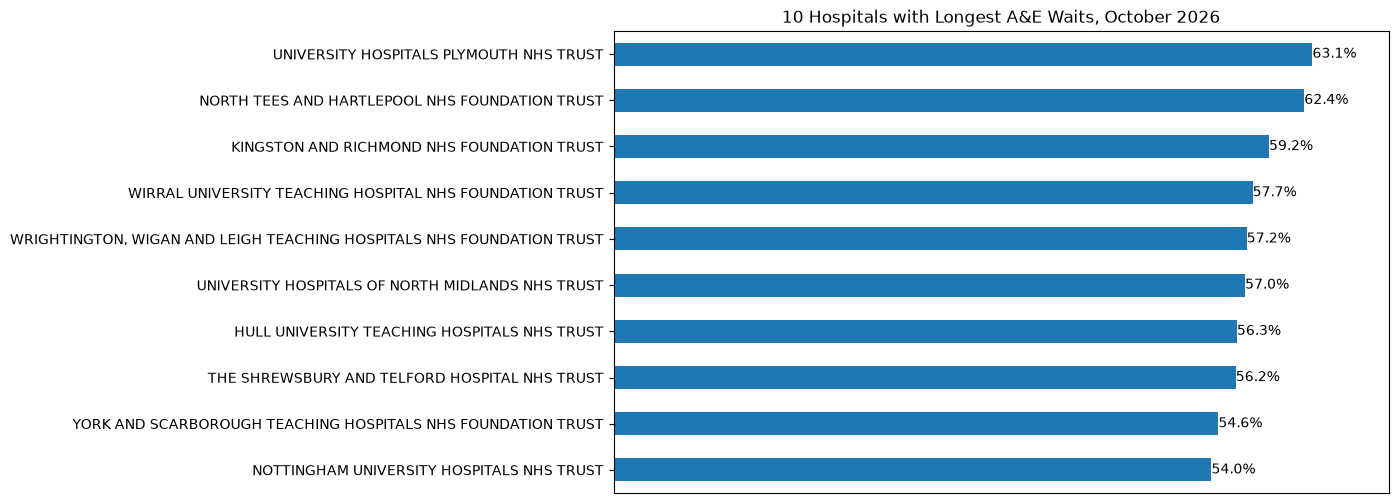

In [28]:
import matplotlib.pyplot as plt
ax = top10.sort_values("% over 4hrs").plot.barh(x="Org name", y="% over 4hrs", figsize=(10,6), title="10 Hospitals with Longest A&E Waits, October 2026", legend=False)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set_xlim(0, 70)
ax.set_xticks([])
ax.set_ylabel("")
plt.savefig("NHS AE Longest Waits October 2026.png", bbox_inches="tight")

## Key Findings
- Across England, 40.1% of patients at major A&Es waited over 4 hours.
-  University Hospitals Plymouth had the longest waits: 63.1% waited over 4 hours.
-  Children's hospitals had the shortest waits (Alder Hey 12.2%); among general hospitals, Calderdale and Huddersfield did best (17.1%).